# 30장 · LangGraph의 검색 노드와 답변 노드

검색 노드는 질문에서 관련 문서를 찾고, 답변 노드는 그 문서를 읽습니다. 두 노드가 공유할 상태에 본문과 출처를 함께 담습니다.

검색 문장을 화면에 그대로 띄우면 어느 쪽의 안내인지 찾기 어렵습니다. 26장에서 문자열로 담았던 검색 결과에 문서 ID, 원문 제목, 쪽수를 함께 싣고 같은 검색 함수를 그래프 안에서 호출합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 langgraph 1.2.16입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## retrieve()의 문서와 출처 반환

노트북의 자료는 앞서 사용한 가상 도서관 안내 세 쪽입니다. 읽는 법에 집중하려고 로컬 검색 함수는 세 낱말의 유무를 거리로 바꾸며 k개를 고릅니다. Chroma 서버나 외부 임베딩을 호출하는 셀은 없습니다.


### 셀 01 · retrieve()의 문서 메타데이터

대출 질문을 넣고 목록의 첫 번째 레코드를 읽으세요.


In [1]:
records = [{'id': 'library-1',
  'text': '도서 대출 기간은 14일입니다.',
  'source': '가상 도서관 이용 안내',
  'page': 1},
 {'id': 'library-2',
  'text': '도서관은 월요일에 휴관합니다.',
  'source': '가상 도서관 이용 안내',
  'page': 2},
 {'id': 'library-3',
  'text': '무인 반납함은 24시간 이용할 수 있습니다.',
  'source': '가상 도서관 이용 안내',
  'page': 3}]
terms = ("대출", "휴관", "반납")

def retrieve(question, k=1):
    query = [int(term in question) for term in terms]
    if not any(query):
        return []
    def distance(row):
        vector = [int(term in row["text"]) for term in terms]
        return sum((a-b)**2 for a, b in zip(query, vector)), row["id"]
    return sorted(records, key=distance)[:k]

print(retrieve('대출 기간은?', 1)[0])

{'id': 'library-1', 'text': '도서 대출 기간은 14일입니다.', 'source': '가상 도서관 이용 안내', 'page': 1}


library-1에 14일이라는 문장, 가상 도서관 이용 안내, 1쪽이 함께 있습니다. text만 남기면 다음 노드에서 출처를 복원할 수 없습니다.


### retrieve(question, k)의 반환값

<p>검색에 쓰는 세 낱말은 대출·휴관·반납입니다. 하나도 들어 있지 않으면 빈 리스트를 돌려줍니다. 일치하는 낱말이 있으면 거리와 문서 ID로 정렬한 뒤 앞의 k개를 반환합니다. 셀 01은 k=1의 첫 레코드를 출력합니다.</p>


### 문장에 출처와 쪽 번호를 함께 보관하기

<p>26장에서는 documents의 원소가 문자열이었습니다. 여기서는 한 문서를 id·text·source·page 네 필드로 받습니다. 답변에는 text를 쓰고, 어떤 자료의 몇 쪽인지 확인할 때는 같은 레코드에서 source와 page를 읽습니다.</p>


## StateGraph에 검색·답변 노드 연결

검색 결과를 상태에 넣을 때는 documents 키에 목록을 그대로 반환합니다. 다음 노드는 같은 목록에서 답을 꺼냅니다. 별도로 다시 검색하면 처음 확인한 근거와 다른 문서를 답에 쓰게 될 수 있습니다.

<!-- lesson-visual visual-required -->
**검색 노드에서 답변까지 따라가는 문서 한 건**

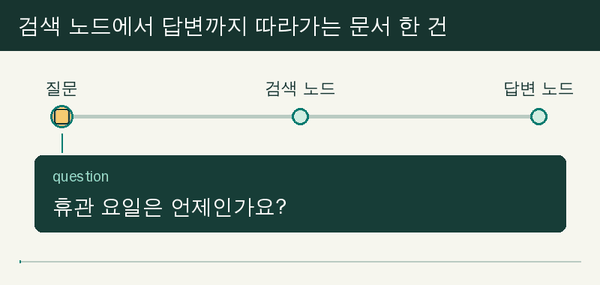

휴관 질문은 library-2를 찾습니다. 답변 노드가 문서 본문으로 답을 만듭니다. 쪽 번호 2는 최종 상태의 documents에서 따로 읽습니다.
<!-- /lesson-visual visual-required -->


### 같은 레코드의 본문과 페이지가 서로 다른 곳으로 갑니다

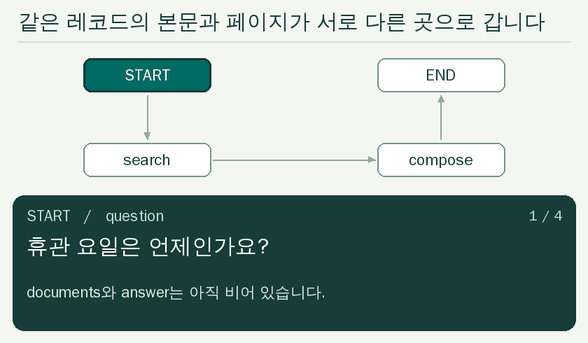

그래프 이름 compose에 등록한 함수는 answer_node입니다. 이 함수는 answer만 반환합니다. 쪽 번호는 END의 documents에서 읽습니다.


### 셀 02 · 검색·답변 노드를 간선으로 연결

아래 그래프에서 START 다음에 연결한 노드를 찾고 휴관 질문을 실행하세요.

이 노트북의 retrieve는 공백 질문에서 []를 반환하고 답변은 상태의 answer에서 읽습니다. 뒤의 R1/A1 참고 구현은 공백을 ValueError로 처리하며 result 안에 답을 넣습니다. 두 구현의 키를 섞으면 값을 찾을 수 없습니다.


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
class State(TypedDict):
    question: str
    documents: list[dict]
    answer: str

def search_node(state):
    return {"documents": retrieve(state["question"], k=1)}

def answer_node(state):
    docs = state["documents"]
    return {"answer": docs[0]["text"] if docs else "제공된 자료에서 확인할 수 없습니다."}

builder = StateGraph(State)
builder.add_node("search", search_node)
builder.add_node("compose", answer_node)
builder.add_edge(START, "search")
builder.add_edge("search", "compose")
builder.add_edge("compose", END)
graph = builder.compile()

request = {'question': '휴관 요일은 언제인가요?', 'documents': [], 'answer': ''}
result = graph.invoke(request)
print(result['answer'], result['documents'][0]['page'])

도서관은 월요일에 휴관합니다. 2


월요일이라는 답 뒤에 2가 붙습니다. 검색 함수가 고른 2쪽을 compose가 그대로 읽었습니다. 답 옆의 숫자는 결과 순위가 아닌 원문의 쪽수입니다. result는 실행 결과 전체의 변수 이름입니다. 답은 result["answer"], 원문 쪽수는 result["documents"][0]["page"]에서 읽습니다.


### 검색 노드가 쓰는 필드와 답변 노드가 읽는 필드

<p>search_node는 documents만 반환합니다. 다음 compose 노드는 그 목록에서 첫 문서의 text를 꺼내 answer를 씁니다. 마지막 print에서 page를 읽을 수 있는 이유는 검색 노드가 넘긴 문서가 결과 상태에 남기 때문입니다.</p>


### 과제 03 · 빈 검색 결과의 응답 분기

‘주차 요금은?’을 넣고 documents와 answer를 차례로 확인하세요.


In [3]:
# 초기 상태의 질문을 바꾸어 그래프를 실행하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>empty = graph.invoke({**request, &#x27;question&#x27;: &#x27;주차 요금은?&#x27;})
print(empty[&#x27;documents&#x27;], empty[&#x27;answer&#x27;])</code></pre>
<p>실행 결과</p><pre><code>[] 제공된 자료에서 확인할 수 없습니다.</code></pre>
<p>빈 목록과 확인할 수 없다는 안내가 나옵니다. 세 낱말 모두 질문에 없어 검색 함수가 빈 목록을 돌려준 경우입니다. 연결 오류에 같은 안내를 쓰면 장애가 가려집니다.</p>
</details>


### 검색에 성공했지만 근거가 없을 때

<p>주차 질문에는 자료의 세 낱말이 없습니다. search가 빈 리스트를 기록해도 고정 간선은 compose로 이어집니다. compose가 빈 리스트를 읽고 안내를 씁니다. 다음 장에서는 검색 함수가 예외를 낸 경우와 비교합니다.</p>


### 검색 결과가 비어도 고정 간선은 compose로 갑니다

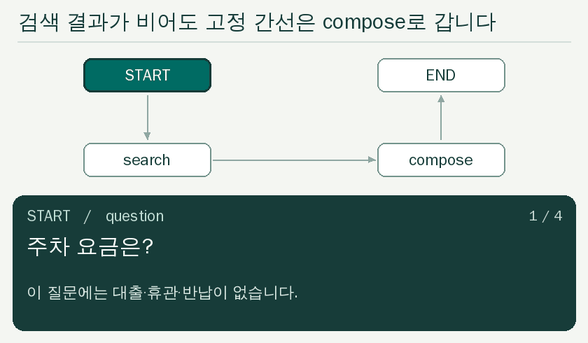

빈 리스트는 정상 반환값입니다. search에서 종료하지 않고 compose가 목록 길이에 맞는 안내를 고릅니다.


## 돌아보기

Chroma에서 같은 결과를 받을 때도 id, text, source, page 네 칸이 필요합니다. 여러 열로 나뉜 반환값을 합칠 때 목록 길이와 쪽수 단위를 확인하세요.
